# Exemple d'anàlisi de dades experimentals

Aquest notebook mostra com utilitzar la llibreria `funcions_labs.py` per:

- expressar magnituds amb incerteses amb el nombre correcte de xifres significatives...
- Fer gràfiques tipus y(x) amb incerteses i possibilitat de posar escales logarítmiques
- Fer ajustos lineals, exponencials, potencials i qualssevol altre dependència
- Obtenir els paràmetres de l'ajustamb incerteses, coeficient de correlació , RMSE i ji quadrat


In [1]:
import numpy as np
from funcions_labs import *

In [2]:
# Per representar correctament un nombre amb incertesa opdem fer servir la funcio format_resultat(valor, incertesa)
# Expressa la incertesa amb una xifra significativa arrodonint-la (a no ser que sigui un 1) 
#expressa el resultat de manera que la mantisa (si cal) sigui un multiple de 3 (per motius estètics)
# llavors posa el valor amb el mateix nombre de decimals i mantisa que la incertesa
dM(format_resultat(234.234,1.275))
dM(format_resultat(434.3445e11,137e8))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [3]:
# Aquí tenim el llistat de tots els models que es poden fer servir per ajustar les dades.
# Son funcions del tipus y(x)=f(x,{a_i}) a on els a_i son els paràmetres de l'ajust
# per mostrar en latex la fòrmula de la funció que fa servir un deteminat model d'ajust 
# cal donar valors arbitraris a la x i a tots els paràmetres.
# i despres especificar la opció option="Text"
dM(model_lineal(0,0,1,option="Text"))
dM(model_exponencial(0,0,1,option="Text"))
dM(model_potencial(0,0,1,option="Text"))
dM(model_gaussià(0,0,1,2,option="Text"))
dM(model_gaussià_base(0,0,1,2,3,4,option="Text"))
dM(model_lorentziana(0,0,1,2,option="Text"))
dM(model_sinus(0,0,1,2,option="Text"))
dM(model_polinomi(0,0,1,2,option="Text")) # el nombre de paràmetres (-1) determinarà el grau del polinomi
dM(model_polinomi(0,0,1,2,3,4,option="Text")+ r" +\,  ...")

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

# Exemple 0. Representar dades sense fer cap mena d'ajust

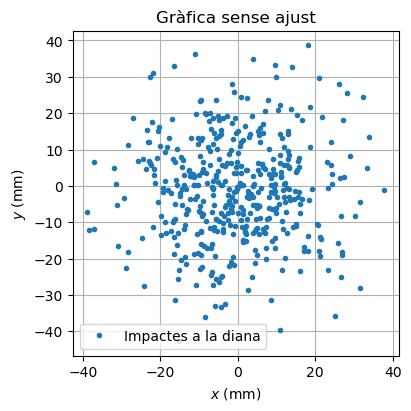

In [4]:
#llegim les dades d'un arxiu de text (amb tabuladors com a separadors de columnes) i saltant-nos la primera fila
x, y = llegeix_dades("Dades_Exemple/dades0.txt",skip=1)

# I fem la gràfica, hem d'especificar les x i les y
# Podem afegir un titol, una etiqueta per les dades, etiquetes als eixos, i la forma del punt ".", "o" o "s"
# per defecte fa servir "o"
ax=mostra_dades(x, y,
    xlabel=r'$x$ (mm)',     ylabel=r'$y$ (mm)',
    titol='Gràfica sense ajust',
    label_dades='Impactes a la diana',
    forma='.',
    mida_figura=(4,4)
)

## Exemple 1: Ajust lineal amb incerteses

<IPython.core.display.Math object>

<IPython.core.display.Math object>

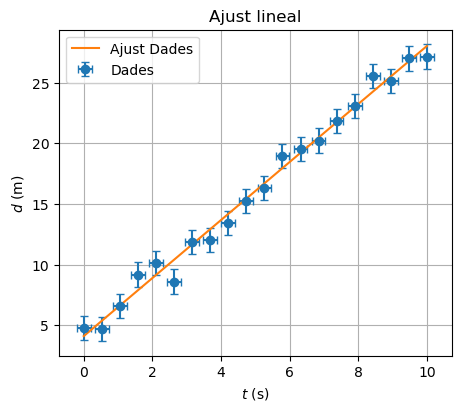

In [5]:
# per fer un ajust hem d'incloure la opcio funcio_model="model". A part del lineal n'hi ha altres definits
# també hem inclós les incerteses en x (fixades a 0.2 s) i en y (llegides de l'arxiu)
x, y, dy = llegeix_dades("Dades_Exemple/dades1.txt",skip=1)
dx=np.full_like(x, 0.2) # i aquestes son les incerteses de les x's
# Mostrem gràfic i ajust
ax=mostra_dades(x, y, incert_y=dy, incert_x=dx,
             funcio_model=model_lineal, 
             titol='Ajust lineal',
             xlabel='$t$ (s)', ylabel='$d$ (m)')


# Exemple 1.1: Ajust lineal dolent

<IPython.core.display.Math object>

<IPython.core.display.Math object>

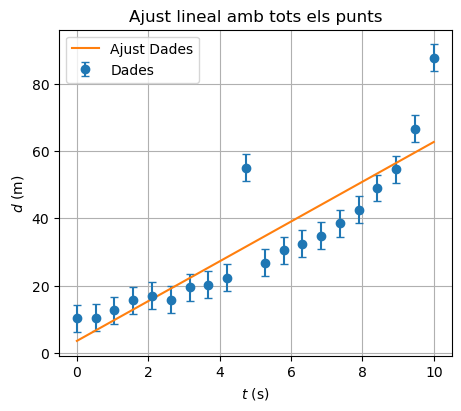

In [6]:
x, y, dy = llegeix_dades("Dades_Exemple/dades1.1.txt",skip=1)
# Mostrem gràfic i ajust
ax=mostra_dades(x, y, incert_y=dy, funcio_model=model_lineal, 
             titol='Ajust lineal amb tots els punts',
             xlabel='$t$ (s)', ylabel='$d$ (m)')

<IPython.core.display.Math object>

<IPython.core.display.Math object>

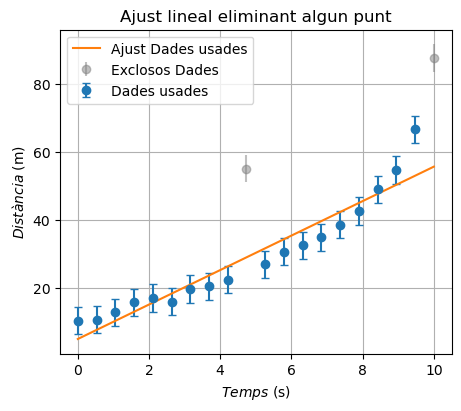

In [7]:
# Mostrem gràfic i l'ajust excloent algun punt en particular (pot ser una llista) 
# exclude=[llista dels punts separats per comes])
ax=mostra_dades(x, y, incert_y=dy, funcio_model=model_lineal, 
             log_x=False, log_y=False, titol='Ajust lineal eliminant algun punt',
             xlabel='$Temps$ (s)', ylabel='$Distància$ (m)',exclude=[9,19])

<IPython.core.display.Math object>

<IPython.core.display.Math object>

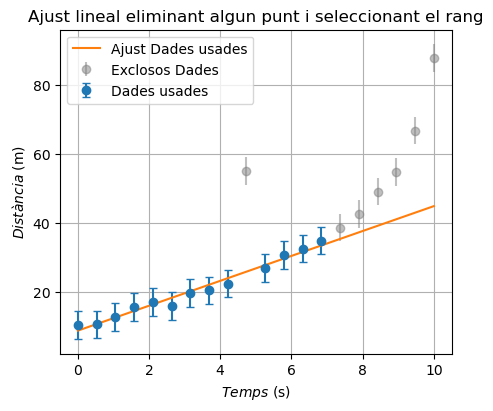

In [8]:
# Mostrem gràfic i ajust
# podem definir el rang que farem servir per fer l'ajust especificant x_min i/o x_max
ax=mostra_dades(x, y, incert_y=dy, funcio_model=model_lineal, 
             titol='Ajust lineal eliminant algun punt i seleccionant el rang',
             xlabel='$Temps$ (s)', ylabel='$Distància$ (m)',
             x_max=7, exclude=[9])

## Mínims quadrats amb mitjanes calculades amb poderació amb les incerteses de les y's

El mètode de minims quadrats simple no considera les incerteses de les y's en cap moment en fer l'ajust.

Aquesta funció (`mostra_dades`), si només es donen les incerteses de les y, fa mínims quadrats ponderats amb l'invers del quadrat de la incertesa. Si es donen incerteses de x i de y, fa una regressió ortogonal que considera els errors de tots dos eixos.

Per desactivar l'ús de les incerteses es pot especificar `ponderacio=False`; les barres d'error es continuen dibuixant, però l'ajust és de mínims quadrats simple.
Si les incerteses de y són constants i no hi ha incertesa en x, els paràmetres ajustats coincideixen amb els de la regressió simple, però les incerteses dels paràmetres no han de coincidir necessàriament.

En aquest exemple es poden veure els ajustos emprant els dos mètodes.

<IPython.core.display.Math object>

<IPython.core.display.Math object>

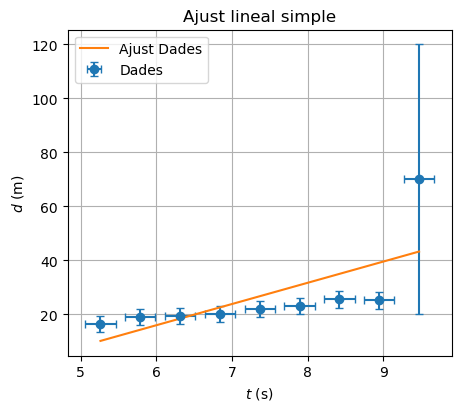

<IPython.core.display.Math object>

<IPython.core.display.Math object>

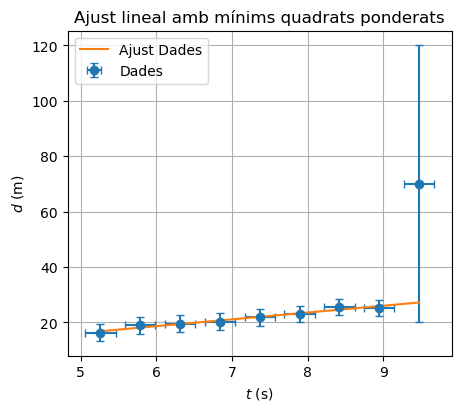

In [9]:
x, y, dy = llegeix_dades("Dades_Exemple/dades1.txt",skip=1)
x=x[10:19]
y=y[10:19]
dx=np.full_like(x, 0.2) # i aquestes son les incerteses de les x's
dy=np.full_like(x, 3)
y[8]=70
dy[8]=50
# Mostrem gràfic i ajust
mostra_dades(x, y, incert_y=dy, incert_x=dx,
             funcio_model=model_lineal, 
             titol='Ajust lineal simple',
             xlabel='$t$ (s)', ylabel='$d$ (m)',ponderacio=False)
# Mostrem gràfic i ajust
ax=mostra_dades(x, y, incert_y=dy, incert_x=dx,
             funcio_model=model_lineal, 
             titol='Ajust lineal amb mínims quadrats ponderats',
             xlabel='$t$ (s)', ylabel='$d$ (m)')

## Exemple 2: Ajust exponencial i representació semi-log

<IPython.core.display.Math object>

<IPython.core.display.Math object>

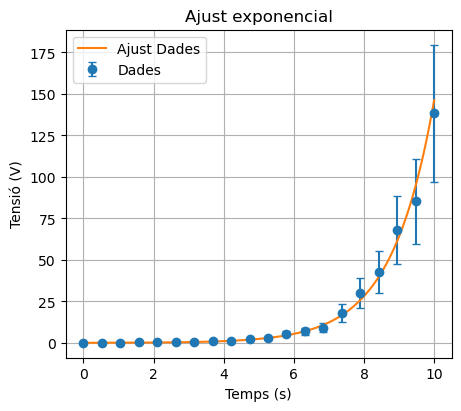

<IPython.core.display.Math object>

<IPython.core.display.Math object>

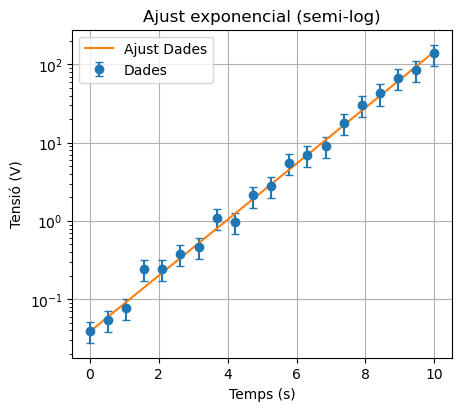

In [10]:
x, y, dy = llegeix_dades("Dades_Exemple/dades2.txt",skip=1)
# Ajust i gràfica fem un ajust exponencial 
ax=mostra_dades(x, y, incert_y=0.3*y, funcio_model=model_exponencial,
             xlabel='Temps (s)', ylabel='Tensió (V)',
             titol='Ajust exponencial')
# Ajust i gràfica fem un ajust exponencial i a part posem un eix en escala logarítmica
ax=mostra_dades(x, y, incert_y=0.3*y, funcio_model=model_exponencial,
             log_y=True, xlabel='Temps (s)', ylabel='Tensió (V)',
             titol='Ajust exponencial (semi-log)')

## Exemple 3: Ajust llei potencial amb representació log-log


<IPython.core.display.Math object>

<IPython.core.display.Math object>

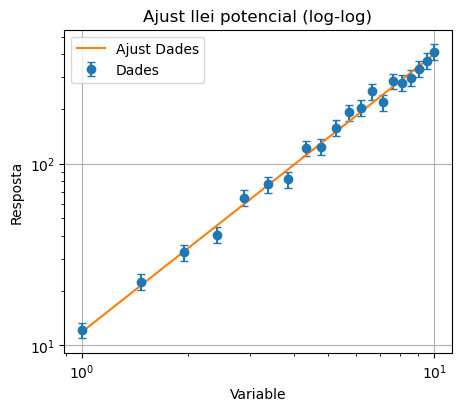

In [11]:
x, y, dy = llegeix_dades("Dades_Exemple/dades3.txt",skip=1)
ax=mostra_dades(x, y, incert_y=dy, funcio_model=model_potencial,
             log_x=True, log_y=True, xlabel='Variable', ylabel='Resposta',
             titol='Ajust llei potencial (log-log)')

## Exemple 4: Ajust a un polinomi de grau arbitrari (3 en aquest cas)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

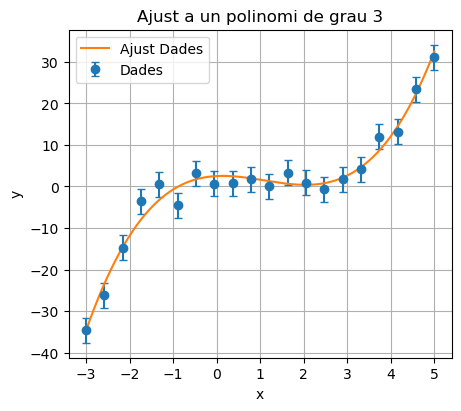

In [12]:
x, y, dy = llegeix_dades("Dades_Exemple/dades4.txt",skip=1)
# Crida a mostra_dades amb el model polinòmic
ax=mostra_dades(x, y,incert_y=dy,
         funcio_model=model_polinomi,
         titol="Ajust a un polinomi de grau 3",
         xlabel="x",ylabel="y",
         forma='o',
         valors_inicials=np.ones(4) #Grau 3 → 4 coeficients
        )

# Exemple 5: ajust a una funció gaussiana

<IPython.core.display.Math object>

<IPython.core.display.Math object>

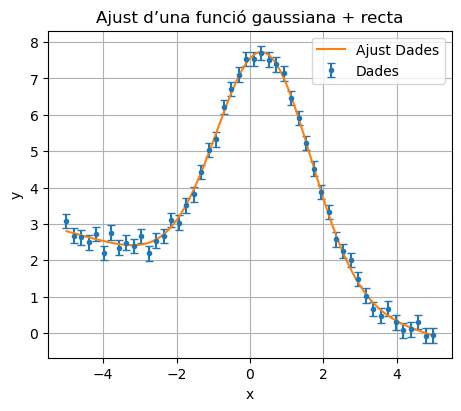

In [13]:
# Dades simulades
x_dades = np.linspace(-5, 5, 50)
y_dades_sense_soroll = model_gaussià_base(x_dades, 6.5, 0.4, 1.3,-0.3,1.33)
# Afegim soroll i incerteses
np.random.seed(1)
soroll = np.random.normal(0, 0.15, size=x_dades.shape)
y_dades = y_dades_sense_soroll + soroll
incerteses_y = 0.2 * np.ones_like(y_dades)

# Cridem a la funció mostra_dades
ax=mostra_dades(
    x_dades, y_dades,
    funcio_model=model_gaussià_base,
    incert_y=incerteses_y,
    xlabel='x',
    ylabel='y',
    titol='Ajust d’una funció gaussiana + recta',
    forma='.'
)

# Exemple 6: Ajust a una lorentziana

<IPython.core.display.Math object>

<IPython.core.display.Math object>

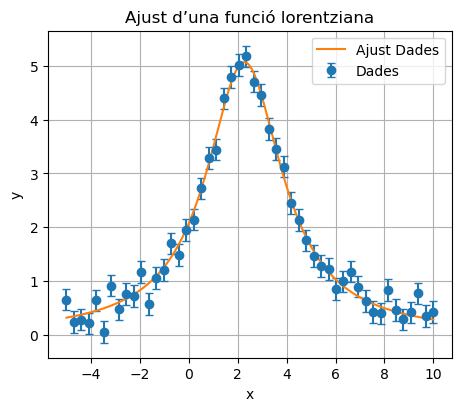

In [14]:
# Dades simulades
x_dades = np.linspace(-5, 10, 50)
y_dades_sense_soroll = model_lorentziana(x_dades, 5.0, 2.3, 1.95)
# Afegim soroll i incerteses
np.random.seed(1)
soroll = np.random.normal(0, 0.2, size=x_dades.shape)
y_dades = y_dades_sense_soroll + soroll
incerteses_y = 0.2* np.ones_like(y_dades)
ax=mostra_dades(
    x_dades, y_dades,
    funcio_model=model_lorentziana,
    incert_y=incerteses_y,
    xlabel='x', ylabel='y',
    titol='Ajust d’una funció lorentziana'
)

## Convergència de l'ajust.
En cas de realitzar un ajust no lineal, no està assegurada la convergència del mètode.
Per mirar de corregir aquest fet es poden donar estimacions dels valors dels paràmetres i així facilitar la convergència.
Cal especificar la opció   valors_inicials=[llista ordenada de les estimacions inicials dels paràmetres]

<IPython.core.display.Math object>

<IPython.core.display.Math object>

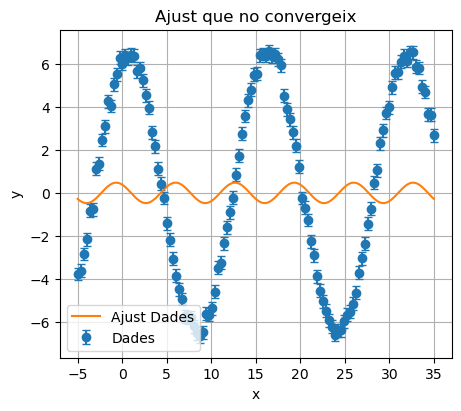

In [15]:
# Dades simulades
x_dades = np.linspace(-5, 35, 120)
y_dades_sense_soroll = model_sinus(x_dades, 6.5, 0.4, 1.3)
# Afegim soroll i incerteses
np.random.seed(1)
soroll = np.random.normal(0, 0.25, size=x_dades.shape)
y_dades = y_dades_sense_soroll + soroll
incerteses_y = 0.3 * np.ones_like(y_dades)
# Cridem a la funció mostra_dades i veiem que no convergeix l'ajust
ax=mostra_dades(
    x_dades, y_dades,
    funcio_model=model_sinus,
   incert_y=incerteses_y,
    xlabel='x',
    ylabel='y',
    titol='Ajust que no convergeix',
    forma='o'
)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

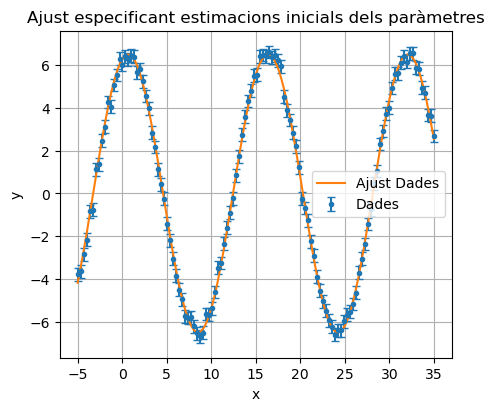

In [16]:
# Cridem a la funció amb una estimació inicial dels paràmetres d'ajust
ax=mostra_dades(
    x_dades, y_dades,
    funcio_model=model_sinus,
   incert_y=incerteses_y,
    xlabel='x',
    ylabel='y',
    titol='Ajust especificant estimacions inicials dels paràmetres',
    forma='.',
    valors_inicials=[6,.5,0]
)

## Definició d'un model d'ajust personalitzat
Pots definir la teva propia funció d'ajust per fer servir amb mostra_dades.
En aquest exemple es crea una funció sigmoidal i s'ajusten unes dades inventades.

<IPython.core.display.Math object>

<IPython.core.display.Math object>

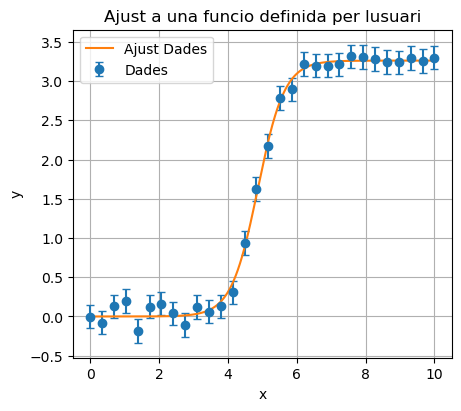

In [17]:
#definim el nostre model
def el_meu_model (x, a, b,c, ** kwargs ):
    if kwargs.get("option") == "Text":
        return r"y = \frac{a_0 }{1+ e^{- a_1 (x-a_2)}}"
    return a /(1+ np. exp (-b * (x-c)))
#ens invemtem unes dades    
x1 = np.linspace(0, 10, 30)
y1 = 3.23/(1+np.exp(-2.6*( x1-4.86)) )+ np.random.normal(0, 0.1, len(x1))
dy1 = np.full_like(x1, 0.15)
#fem la representació i l'ajust
ax=mostra_dades(
    x1, y1,incert_y=dy1,
    funcio_model = el_meu_model,        # fem servir el nostre model per fer l'ajust
    xlabel='x',     ylabel='y',
    titol='Ajust a una funcio definida per lusuari'
) 

## Funció mostra_varies_series
Per representar (i ajustar) diverses sèries de dades a la mateixa gràfica.

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

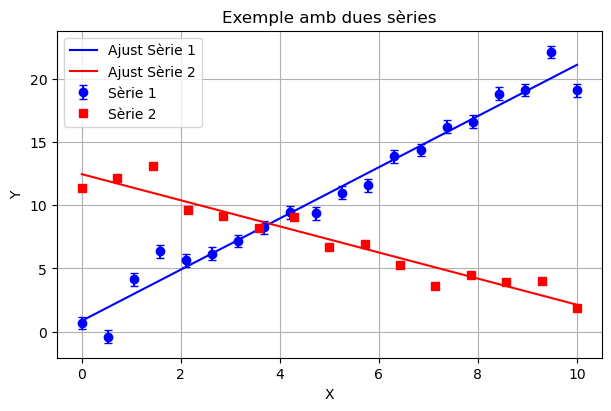

In [18]:
x1 = np.linspace(0, 10, 20)
y1 = 2.0 * x1 + 1.0 + np.random.normal(0, 1, len(x1))
dy1 = np.full_like(x1, 0.5)

x2 = np.linspace(0, 10, 15)
y2 = -1.0 * x2 + 12.0 + np.random.normal(0, 1, len(x2))

series = [
    {"x": x1, "y": y1, "incert_y": dy1,
     "funcio_model": model_lineal,
     "label_dades": "Sèrie 1", "forma": "o", "color": "blue"},
     
    {"x": x2, "y": y2,
     "funcio_model": model_lineal,
     "label_dades": "Sèrie 2", "forma": "s", "color": "red"}
]

ax=mostra_varies_series(series, xlabel="X", ylabel="Y",
                     titol="Exemple amb dues sèries")

Un altre exemple més complex.

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

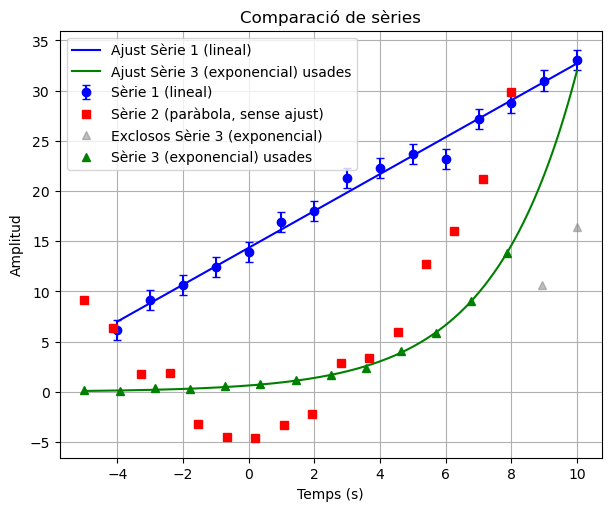

In [19]:
# Dades per a la sèrie 1 (lineal)
x1 = np.linspace(-4, 10, 15)
y1 = 1.8 * x1 + 14.0 + np.random.normal(0, 1, size=len(x1))   # y = 2x + 1 + soroll
dy1 = np.ones_like(x1) * 1.0  # incertesa constant

# Dades per a la sèrie 2 (paràbola sense ajust, només representació)
x2 = np.linspace(-5, 8, 16)
y2 = 0.5 * x2**2 - 3 + np.random.normal(0, 1, size=len(x2))

# Dades per a la sèrie 3 (exponencial)
x3 = np.linspace(-5, 10, 15)
y3 = 0.6 * np.exp(0.4 * x3) + np.random.normal(0, .1, size=len(x3))
y3[13:15]=y3[13:15]/2

# Ara fem la gràfica amb les 3 sèries
ax=mostra_varies_series([
    {"x": x1, "y": y1, "funcio_model": model_lineal, 
     "label_dades": "Sèrie 1 (lineal)", "incert_y": dy1, "forma": "o", "color": "blue"},
    
    {"x": x2, "y": y2, "label_dades": "Sèrie 2 (paràbola, sense ajust)", 
     "forma": "s", "color": "red"},
    
    {"x": x3, "y": y3, "funcio_model": model_exponencial, 
     "label_dades": "Sèrie 3 (exponencial)", "valors_inicials": [2, 0.5], 
     "forma": "^", "color": "green", "x_max": 8},
]
, xlabel="Temps (s)", ylabel="Amplitud", titol="Comparació de sèries", mida_figura=(6,5))

## Utilitats dels objectes retornats
`mostra_dades` retorna la parella `(ax, resultats)`. `ax` és l'objecte de Matplotlib que permet desar i modificar la figura; `resultats` és el diccionari de l'ajust, o `None` si no s'ha indicat cap model. `mostra_varies_series` retorna només `ax`.

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

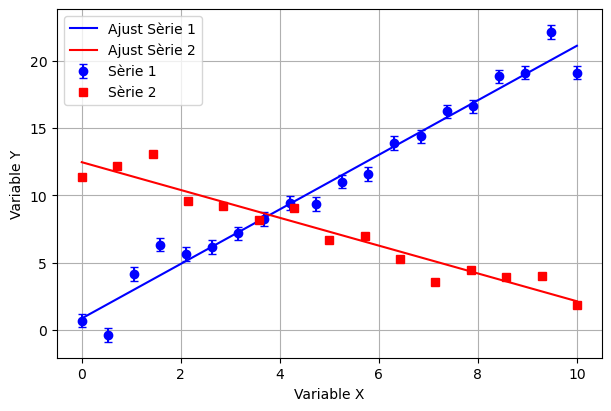

In [20]:
#tornem a fer la figura i la desem
ax = mostra_varies_series(series, xlabel="Variable X", ylabel="Variable Y")
ax.figure.savefig("dues_series.png", dpi=150)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

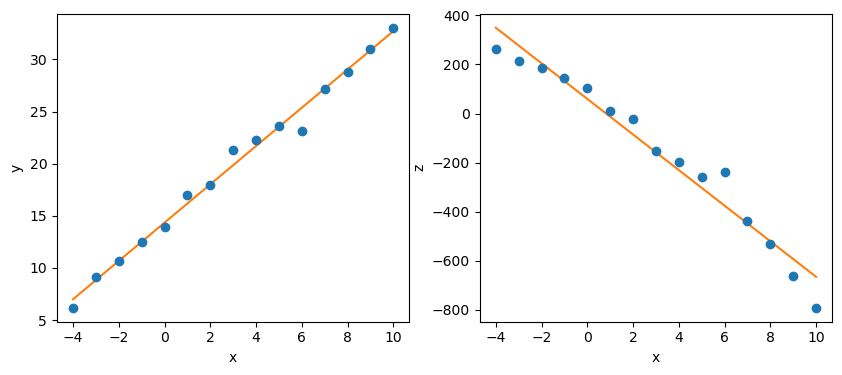

In [21]:
#fem una nova figura amb dues (una al costat de l'altra
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10,4))
ax1, resultats1 = mostra_dades(x1, y1, funcio_model=model_lineal, ax=ax1)
ax2, resultats2 = mostra_dades(x1, 300-y1**2, funcio_model=model_lineal,ylabel="z", ax=ax2)


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

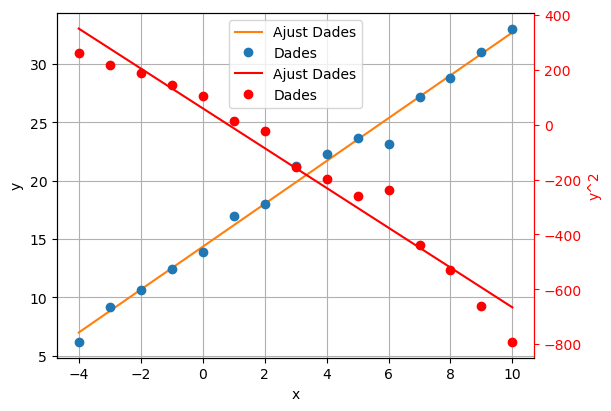

In [22]:
#fer una figura amg dues sèries i dos eixos diferents . el segon el pinta d'un altre color
fig, ax1 = plt.subplots(figsize=(6,4), constrained_layout=True)
ax2 = ax1.twinx()
ax1, resultats1 = mostra_dades(x1, y1, funcio_model=model_lineal, ax=ax1)
ax2, resultats2 = mostra_dades(x1, 300-y1**2, funcio_model=model_lineal,ylabel="z",color='red', ax=ax2)
ax2.set_ylabel("y^2", color="red")       # etiqueta vermella
ax2.tick_params(axis="y", colors="red")  # ticks i nombres vermells
ax2.spines["right"].set_color("red")
# 5. Llegenda combinada
lns1, labs1 = ax1.get_legend_handles_labels()
lns2, labs2 = ax2.get_legend_handles_labels()
ax1.legend(lns1+lns2, labs1+labs2, loc="upper center")
ax1.grid(True)
plt.show()